In [1]:
import wfdb
import numpy as np
import pandas as pd
import scipy
import matplotlib.pyplot as plt
import sklearn
import torch

print("All libraries imported successfully!")
print("PyTorch version:", torch.__version__)

Matplotlib is building the font cache; this may take a moment.


All libraries imported successfully!
PyTorch version: 2.15.0


In [2]:
from pathlib import Path
from collections import Counter

import wfdb
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Locate the project directory
cwd = Path.cwd()
PROJECT_ROOT = cwd.parent if cwd.name == "notebooks" else cwd

RAW_DIR = PROJECT_ROOT / "data" / "raw"

print("Data directory:", RAW_DIR)
print("Recordings found:", len(list(RAW_DIR.glob("*.hea"))))

Data directory: /Users/priyachoudhary/DS-6050-Group-9-Project/data/raw
Recordings found: 48


In [3]:
record = wfdb.rdrecord(str(RAW_DIR / "100"))
annotation = wfdb.rdann(str(RAW_DIR / "100"), "atr")

print("Sampling frequency:", record.fs)
print("Signal shape:", record.p_signal.shape)
print("ECG channels:", record.sig_name)
print("Number of annotations:", len(annotation.sample))
print("Annotation distribution:", Counter(annotation.symbol))

Sampling frequency: 360
Signal shape: (650000, 2)
ECG channels: ['MLII', 'V5']
Number of annotations: 2274
Annotation distribution: Counter({'N': 2239, 'A': 33, '+': 1, 'V': 1})


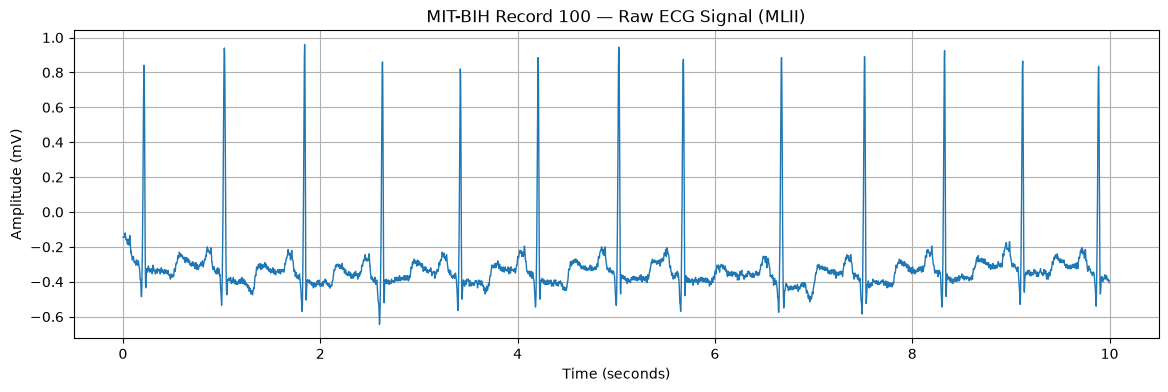

In [4]:
# Sampling frequency
fs = int(record.fs)

# Select the MLII channel (first channel)
signal = record.p_signal[:, 0]

# Plot the first 10 seconds
duration = 10
num_samples = duration * fs

time = np.arange(num_samples) / fs

plt.figure(figsize=(14, 4))

plt.plot(time, signal[:num_samples], linewidth=1)

plt.title("MIT-BIH Record 100 — Raw ECG Signal (MLII)")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.grid(True)

plt.show()

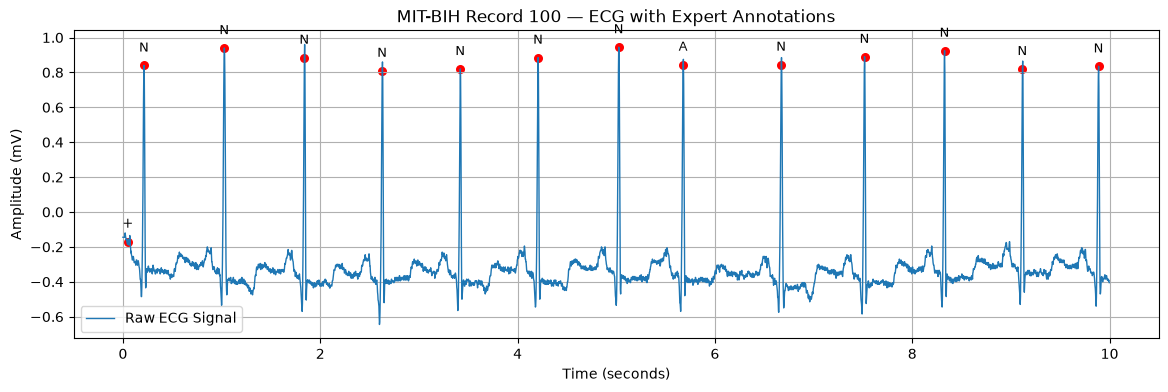

In [5]:
# Select annotations within the first 10 seconds
mask = annotation.sample < num_samples

beat_samples = annotation.sample[mask]
beat_symbols = np.array(annotation.symbol)[mask]

plt.figure(figsize=(14, 4))

plt.plot(
    time,
    signal[:num_samples],
    label="Raw ECG Signal",
    linewidth=1
)

# Add annotation markers
for sample, symbol in zip(beat_samples, beat_symbols):

    if sample < len(signal):

        plt.scatter(
            sample / fs,
            signal[sample],
            color="red",
            s=30
        )

        plt.annotate(
            symbol,
            (sample / fs, signal[sample]),
            xytext=(0, 10),
            textcoords="offset points",
            ha="center",
            fontsize=9
        )

plt.title("MIT-BIH Record 100 — ECG with Expert Annotations")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(True)

plt.show()

In [6]:
from scipy.signal import butter, sosfiltfilt

# Define bandpass filter
lowcut = 0.5
highcut = 40.0
filter_order = 4

# Create Butterworth bandpass filter
sos = butter(
    filter_order,
    [lowcut, highcut],
    btype="bandpass",
    fs=fs,
    output="sos"
)

# Apply zero-phase filtering to the MLII signal
filtered_signal = sosfiltfilt(sos, signal)

print("Original signal shape:", signal.shape)
print("Filtered signal shape:", filtered_signal.shape)
print("Filtering completed successfully!")

Original signal shape: (650000,)
Filtered signal shape: (650000,)
Filtering completed successfully!


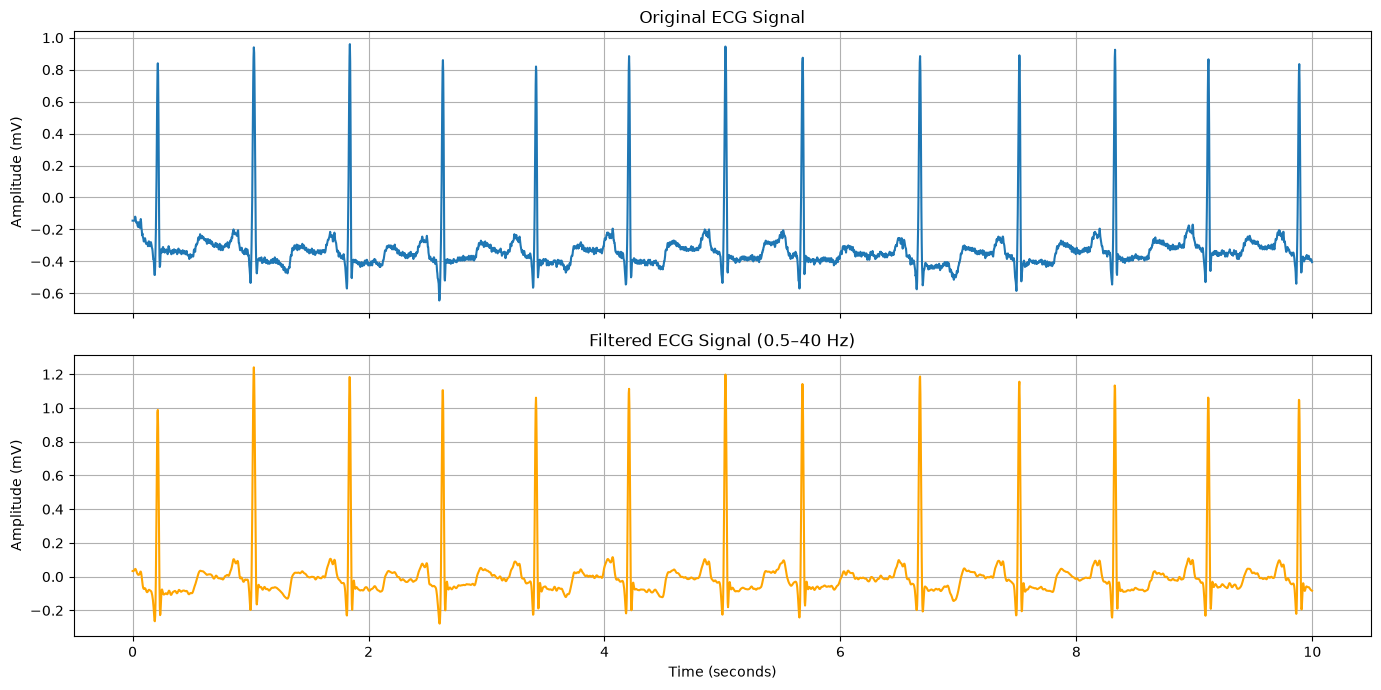

In [7]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

axes[0].plot(time, signal[:num_samples])
axes[0].set_title("Original ECG Signal")
axes[0].set_ylabel("Amplitude (mV)")
axes[0].grid(True)

axes[1].plot(time, filtered_signal[:num_samples], color="orange")
axes[1].set_title("Filtered ECG Signal (0.5–40 Hz)")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude (mV)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

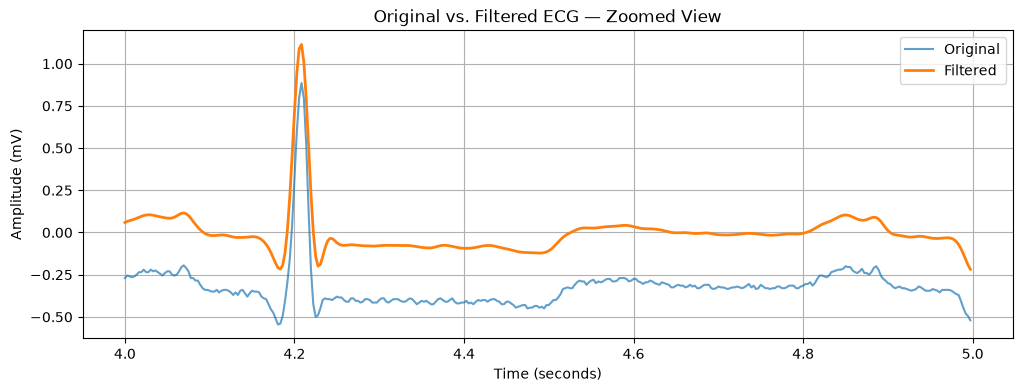

In [8]:
# Zoom into a 1-second interval
start_time = 4.0
end_time = 5.0

start = int(start_time * fs)
end = int(end_time * fs)

zoom_time = np.arange(start, end) / fs

plt.figure(figsize=(12, 4))

plt.plot(
    zoom_time,
    signal[start:end],
    label="Original",
    alpha=0.7
)

plt.plot(
    zoom_time,
    filtered_signal[start:end],
    label="Filtered",
    linewidth=2
)

plt.title("Original vs. Filtered ECG — Zoomed View")
plt.xlabel("Time (seconds)")
plt.ylabel("Amplitude (mV)")
plt.legend()
plt.grid(True)
plt.show()

In [9]:
# Map MIT-BIH beat annotations to five AAMI-style categories

BEAT_CLASSES = {
    # Normal and bundle branch block beats
    "N": 0,
    "L": 0,
    "R": 0,
    "e": 0,
    "j": 0,

    # Supraventricular ectopic beats
    "A": 1,
    "a": 1,
    "J": 1,
    "S": 1,

    # Ventricular ectopic beats
    "V": 2,
    "E": 2,

    # Fusion beats
    "F": 3,

    # Unknown and paced beats
    "/": 4,
    "f": 4,
    "Q": 4
}

CLASS_NAMES = {
    0: "N - Normal",
    1: "S - Supraventricular",
    2: "V - Ventricular",
    3: "F - Fusion",
    4: "Q - Unknown/Paced"
}

print("Number of classes:", len(CLASS_NAMES))
print("Classes:", CLASS_NAMES)

Number of classes: 5
Classes: {0: 'N - Normal', 1: 'S - Supraventricular', 2: 'V - Ventricular', 3: 'F - Fusion', 4: 'Q - Unknown/Paced'}


In [10]:
# Number of samples before and after each annotated heartbeat
samples_before = 90
samples_after = 162

X_beats = []
y_beats = []

for sample, symbol in zip(annotation.sample, annotation.symbol):

    # Skip annotations that are not recognized heartbeat classes
    if symbol not in BEAT_CLASSES:
        continue

    start = sample - samples_before
    end = sample + samples_after

    # Skip beats too close to the beginning or end
    if start < 0 or end > len(filtered_signal):
        continue

    # Extract heartbeat
    beat = filtered_signal[start:end]

    # Assign class label
    label = BEAT_CLASSES[symbol]

    X_beats.append(beat)
    y_beats.append(label)

# Convert to NumPy arrays
X_beats = np.array(X_beats, dtype=np.float32)
y_beats = np.array(y_beats, dtype=np.int64)

print("Heartbeat data shape:", X_beats.shape)
print("Label data shape:", y_beats.shape)
print("Class distribution:")

for class_id, class_name in CLASS_NAMES.items():
    count = np.sum(y_beats == class_id)
    print(f"{class_name}: {count}")

Heartbeat data shape: (2271, 252)
Label data shape: (2271,)
Class distribution:
N - Normal: 2237
S - Supraventricular: 33
V - Ventricular: 1
F - Fusion: 0
Q - Unknown/Paced: 0


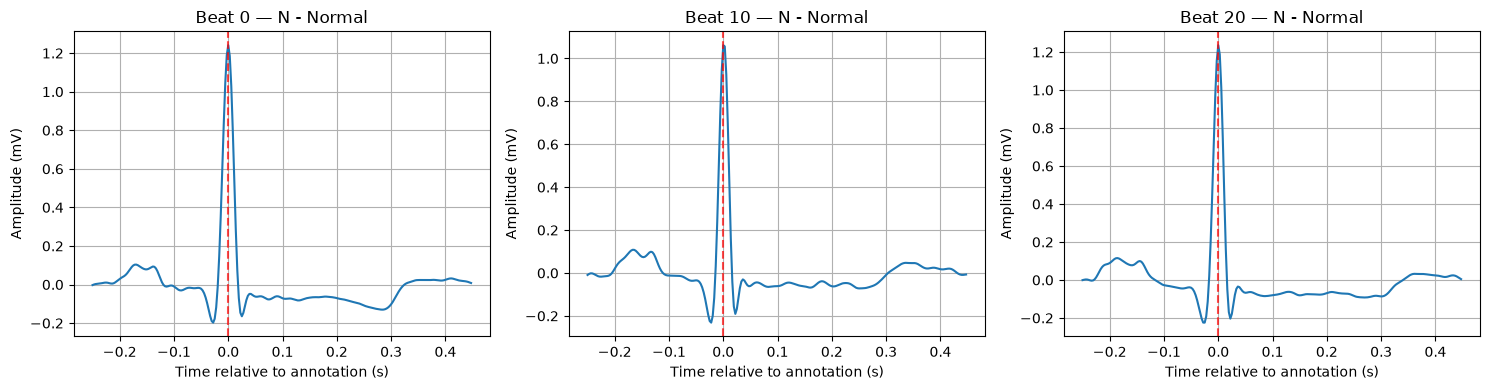

In [11]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# Select three heartbeat examples
example_indices = [0, 10, 20]

for ax, idx in zip(axes, example_indices):

    beat = X_beats[idx]
    label = y_beats[idx]

    beat_time = (
        np.arange(len(beat)) - samples_before
    ) / fs

    ax.plot(beat_time, beat)

    ax.axvline(
        x=0,
        color="red",
        linestyle="--",
        alpha=0.7,
        label="Annotation"
    )

    ax.set_title(f"Beat {idx} — {CLASS_NAMES[label]}")
    ax.set_xlabel("Time relative to annotation (s)")
    ax.set_ylabel("Amplitude (mV)")
    ax.grid(True)

plt.tight_layout()
plt.show()

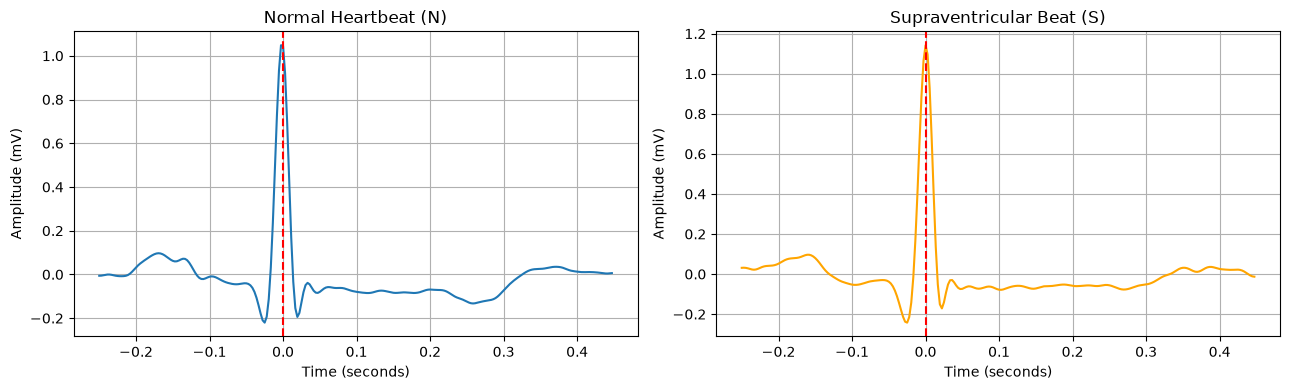

In [12]:
# Find indices of normal and supraventricular beats
normal_indices = np.where(y_beats == 0)[0]
sv_indices = np.where(y_beats == 1)[0]

# Select one example from each class
normal_beat = X_beats[normal_indices[10]]
sv_beat = X_beats[sv_indices[0]]

# Time relative to annotation
beat_time = (
    np.arange(X_beats.shape[1]) - samples_before
) / fs

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(beat_time, normal_beat)
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Normal Heartbeat (N)")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude (mV)")
axes[0].grid(True)

axes[1].plot(beat_time, sv_beat, color="orange")
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Supraventricular Beat (S)")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude (mV)")
axes[1].grid(True)

plt.tight_layout()
plt.show()

In [13]:
# Get all recording IDs
record_ids = sorted(
    path.stem for path in RAW_DIR.glob("*.hea")
)

all_labels = []
record_summaries = []

for record_id in record_ids:

    ann = wfdb.rdann(
        str(RAW_DIR / record_id),
        "atr"
    )

    # Keep only recognized heartbeat annotations
    labels = [
        BEAT_CLASSES[symbol]
        for symbol in ann.symbol
        if symbol in BEAT_CLASSES
    ]

    all_labels.extend(labels)

    counts = Counter(labels)

    record_summaries.append({
        "Record": record_id,
        "N": counts.get(0, 0),
        "S": counts.get(1, 0),
        "V": counts.get(2, 0),
        "F": counts.get(3, 0),
        "Q": counts.get(4, 0)
    })

# Convert to DataFrame
distribution_df = pd.DataFrame(record_summaries)

display(distribution_df)

print("\nTotal heartbeat distribution:")

for class_id, class_name in CLASS_NAMES.items():
    count = all_labels.count(class_id)
    print(f"{class_name}: {count:,}")

,Record,N,S,V,F,Q
0,100,2239,33,1,0,0
1,101,1860,3,0,0,2
2,102,99,0,4,0,2084
3,103,2082,2,0,0,0
4,104,163,0,2,0,2064
5,105,2526,0,41,0,5
6,106,1507,0,520,0,0
7,107,0,0,59,0,2078
8,108,1740,4,17,2,0
9,109,2492,0,38,2,0



Total heartbeat distribution:
N - Normal: 90,631
S - Supraventricular: 2,781
V - Ventricular: 7,236
F - Fusion: 803
Q - Unknown/Paced: 8,043


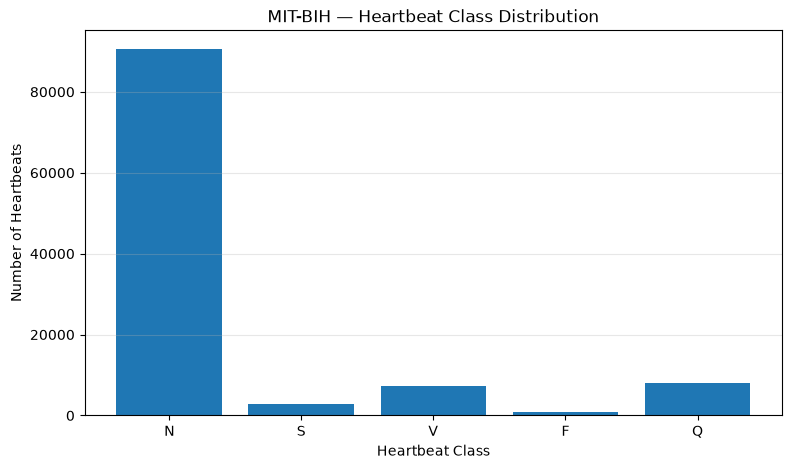

In [14]:
class_counts = [
    all_labels.count(i)
    for i in range(5)
]

class_labels = ["N", "S", "V", "F", "Q"]

plt.figure(figsize=(9, 5))

plt.bar(class_labels, class_counts)

plt.title("MIT-BIH — Heartbeat Class Distribution")
plt.xlabel("Heartbeat Class")
plt.ylabel("Number of Heartbeats")
plt.grid(axis="y", alpha=0.3)

plt.show()